In [1]:
import hashlib
import random
import math
import numpy as np
import pylab as plt

In [ ]:
for i in range(10):
  a = random.randint(0,2**32)
  print(a,bin(a))

2748992697 0b10100011110110100100110010111001
1899898512 0b1110001001111100010011010010000
939217284 0b110111111110110101000110000100
3183061577 0b10111101101110011010101001001001
1508550302 0b1011001111010101010011010011110
830380466 0b110001011111101001100110110010
3286833644 0b11000011111010010001100111101100
3147456153 0b10111011100110100101111010011001
3056027464 0b10110110001001110100011101001000
3603404526 0b11010110110001111001011011101110


http://algo.inria.fr/flajolet/Publications/FlFuGaMe07.pdf 


http://algo.inria.fr/flajolet/Publications/src/FlMa85.pdf


#Generate random set for certain size 

In [2]:
def generate_random_set(size):
  random_number = random.randrange(1,2**32)
  random_set = {random_number}
  for i in range(size-1):
    random_set.add(random.randrange(1,2**32))
  return random_set

In [ ]:
generate_random_set(10)

{22266954,
 1254830530,
 1271943664,
 1839314012,
 2433943437,
 3102374838,
 3219615667,
 3260330978,
 3399636203,
 4022593680}

# Find maximum number of leading zeros

In [3]:
def max_zeros_in_set(random_set):
  leading_zeros = []
  for i in random_set:
    leading_zeros.append(max_zeros)
  return max(leading_zeros)

In [ ]:
leadzeros = 0
for i in '00011':
  if i == str(1):
    break
  else:
    leadzeros += 1
print(leadzeros)

3


In [4]:
def count_zeros(str_bin):
  str_bin = str_bin[::-1]
  leadzeros = 0
  for i in str_bin:
    if i == str(1):
      break
    else:
      leadzeros += 1
  return leadzeros

assert 0 == count_zeros(bin(7))
assert 0 == count_zeros(bin(1))
assert 1 == count_zeros(bin(2))
assert 4 == count_zeros(bin(16))
assert 3 == count_zeros(bin(53130088456))

In [ ]:
def plot_histogram_zeros(random_set):
  lead_zero_to_count = [count_zeros(bin(x)) for x in random_set]
  histogram_full = plt.hist(lead_zero_to_count,range(max(lead_zero_to_count)))
  plt.show()
def tail(random_set,bins_from_tail):
  lead_zero_to_count = [count_zeros(bin(x)) for x in random_set] 
  tail = plt.hist(lead_zero_to_count,range(max(lead_zero_to_count)- bins_from_tail,max(lead_zero_to_count)+1))
  plt.show()

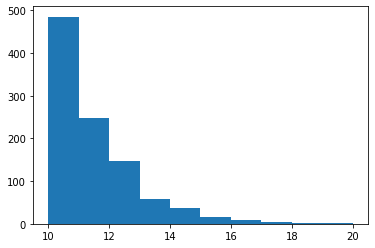

In [ ]:
tail(generate_random_set(1000000),10)

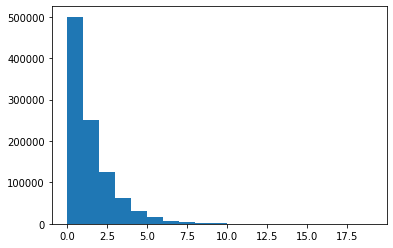

In [ ]:
plot_histogram_zeros(generate_random_set(1000000))

(array([3., 0.]), array([1, 2, 3]), <a list of 2 Patch objects>)

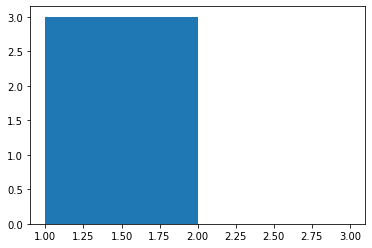

In [ ]:
plt.hist([1,1,1],[1,2,3])

In [ ]:
max_number = 29
for i in range(10000):
  test = max_zeros_in_set(generate_random_set(1000))
  if test != 29:
    print('Fail')

In [5]:
def run_experiment(step,max_size):
  x = []
  y = []
  for i in range(1000,max_size,step):
    x.append(i)
    random_set = generate_random_set(i)
    max_zeros = max_zeros_in_set(random_set)
    y.append(max_zeros)
  return x,y

In [ ]:
max_num = 0
for i in range(1,1000):
  if math.log2(i) > max_num:
    max_num = math.log2(i)
print(max_num)

9.964340867792417


In [ ]:
run_experiment(10,10000)

([1000,
  1010,
  1020,
  1030,
  1040,
  1050,
  1060,
  1070,
  1080,
  1090,
  1100,
  1110,
  1120,
  1130,
  1140,
  1150,
  1160,
  1170,
  1180,
  1190,
  1200,
  1210,
  1220,
  1230,
  1240,
  1250,
  1260,
  1270,
  1280,
  1290,
  1300,
  1310,
  1320,
  1330,
  1340,
  1350,
  1360,
  1370,
  1380,
  1390,
  1400,
  1410,
  1420,
  1430,
  1440,
  1450,
  1460,
  1470,
  1480,
  1490,
  1500,
  1510,
  1520,
  1530,
  1540,
  1550,
  1560,
  1570,
  1580,
  1590,
  1600,
  1610,
  1620,
  1630,
  1640,
  1650,
  1660,
  1670,
  1680,
  1690,
  1700,
  1710,
  1720,
  1730,
  1740,
  1750,
  1760,
  1770,
  1780,
  1790,
  1800,
  1810,
  1820,
  1830,
  1840,
  1850,
  1860,
  1870,
  1880,
  1890,
  1900,
  1910,
  1920,
  1930,
  1940,
  1950,
  1960,
  1970,
  1980,
  1990,
  2000,
  2010,
  2020,
  2030,
  2040,
  2050,
  2060,
  2070,
  2080,
  2090,
  2100,
  2110,
  2120,
  2130,
  2140,
  2150,
  2160,
  2170,
  2180,
  2190,
  2200,
  2210,
  2220,
  2230,
  2240,


#Log Likelihood

# Exponential

In [5]:
def ll_expo(Xi,n):
  total_sum = 0
  for i in Xi:
    total_sum += i
  return n/total_sum

In [7]:
def random_numbers(n):
  list_n = []
  for i in range(n):
    list_n.append(random.randrange(1,10**11))
  max_zeros = []
  for i in list_n:
    max_zeros.append(count_zeros(bin(i)))
  return max_zeros

In [ ]:
random_numbers(10)

In [ ]:
average_result = 0
for i in range(10):
  result = random_numbers(10000000)
  average_result += ll_expo(result,len(result))
print(average_result/10)

1.0002760779025326


In [ ]:
x1 = []
y1 = []
lambda_1 = 1.0002760779025326
x_points = []
current_number = 0

for i in range(10000):
  x_points.append(current_number)
  current_number += 0.001
for i in x_points:
  x1.append(i)
  y1.append(lambda_1 * math.e ** (-lambda_1 * i))
print(x1,y1)

[0, 0.001, 0.002, 0.003, 0.004, 0.005, 0.006, 0.007, 0.008, 0.009000000000000001, 0.010000000000000002, 0.011000000000000003, 0.012000000000000004, 0.013000000000000005, 0.014000000000000005, 0.015000000000000006, 0.016000000000000007, 0.017000000000000008, 0.01800000000000001, 0.01900000000000001, 0.02000000000000001, 0.02100000000000001, 0.022000000000000013, 0.023000000000000013, 0.024000000000000014, 0.025000000000000015, 0.026000000000000016, 0.027000000000000017, 0.028000000000000018, 0.02900000000000002, 0.03000000000000002, 0.03100000000000002, 0.03200000000000002, 0.03300000000000002, 0.03400000000000002, 0.035000000000000024, 0.036000000000000025, 0.037000000000000026, 0.03800000000000003, 0.03900000000000003, 0.04000000000000003, 0.04100000000000003, 0.04200000000000003, 0.04300000000000003, 0.04400000000000003, 0.04500000000000003, 0.046000000000000034, 0.047000000000000035, 0.048000000000000036, 0.04900000000000004, 0.05000000000000004, 0.05100000000000004, 0.0520000000000

In [ ]:
list_of_expo_mll = []
x_vals = [i for i in range(10,100000,30)]
for i in x_vals:
  ran = random_numbers(i)
  list_of_expo_mll.append(ll_expo(ran,len(ran)))
print(list_of_expo_mll)

[1.4285714285714286, 0.851063829787234, 0.9333333333333333, 0.970873786407767, 1.015625, 1.0666666666666667, 0.9359605911330049, 1.0, 0.9765625, 1.1764705882352942, 0.9451219512195121, 0.9941520467836257, 1.0393258426966292, 1.0050251256281406, 1.1053984575835476, 0.9745762711864406, 0.9760956175298805, 0.935251798561151, 1.0357815442561205, 0.9294871794871795, 1.0217755443886096, 0.9846153846153847, 0.9178082191780822, 0.9523809523809523, 0.9864864864864865, 0.9844559585492227, 0.9495192307692307, 0.9669811320754716, 1.0315533980582525, 1.0538922155688624, 0.9732620320855615, 1.0239651416122004, 1.0777777777777777, 0.9578544061302682, 0.9572490706319703, 1.0422812192723696, 1.0073937153419594, 0.9815950920245399, 1.0267857142857142, 0.9932659932659933, 0.950510604870385, 1.001615508885299, 1.0375816993464053, 0.9454545454545454, 0.9873793615441723, 1.0477657935285054, 0.9837225760792639, 1.0135617416131335, 1.0553129548762736, 0.9979770734996628, 1.0093582887700534, 0.9243697478991597

Text(0, 0.5, 'Value of Lambda')

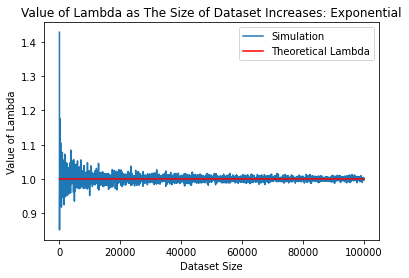

In [ ]:
plt.plot(x_vals,list_of_expo_mll,label="Simulation")
plt.plot(x_vals,[1 for i in range(len(x_vals))],color='r',label="Theoretical Lambda")
plt.legend()
plt.title("Value of Lambda as The Size of Dataset Increases: Exponential")
plt.xlabel("Dataset Size")
plt.ylabel("Value of Lambda")

# Geometric

In [6]:
def ll_geometric(n,xi):
  return n / (n + sum(xi))

In [ ]:
ll_geometric(1,[1])

0.5

In [10]:
def lambda_of_gemetric(n):
  average = 0
  for i in range(n):
    result = random_numbers(10000000)
    average += ll_geometric(len(result),result)
  return average / n

In [ ]:
lambda_of_gemetric(10)

0.5000265559650343

In [ ]:
size = [i for i in range(10,100000,30)]
max_ll_list_geo = []
for i in size:
  result = random_numbers(i)
  max_ll_list_geo.append(ll_geometric(len(result),result))
print(max_ll_list_geo)

[0.5882352941176471, 0.45454545454545453, 0.5, 0.4807692307692308, 0.5263157894736842, 0.5161290322580645, 0.47619047619047616, 0.45267489711934156, 0.49019607843137253, 0.4844290657439446, 0.48589341692789967, 0.5074626865671642, 0.5027173913043478, 0.5215123859191656, 0.4725274725274725, 0.5032822757111597, 0.5141657922350472, 0.49856184084372, 0.5083179297597042, 0.5128205128205128, 0.5160744500846024, 0.4957397366382649, 0.5087319665907365, 0.489853044086774, 0.4876419505678023, 0.4957599478147423, 0.49007444168734493, 0.5061728395061729, 0.49853372434017595, 0.5014245014245015, 0.5244956772334294, 0.5248464544946957, 0.4891578416540595, 0.5094243504839532, 0.49806576402321084, 0.5016564126833886, 0.5086327578161456, 0.5083976395823877, 0.49145299145299143, 0.4804560260586319, 0.5094736842105263, 0.49382716049382713, 0.5011838989739542, 0.4914933837429111, 0.5086042065009561, 0.4929322218194998, 0.4937833037300178, 0.49685094471658503, 0.48755884330867516, 0.49747899159663866, 0.50

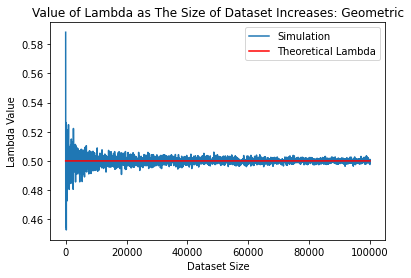

In [ ]:
plt.plot(size,max_ll_list_geo,label='Simulation')
plt.plot(size,[0.5 for i in range(len(size))],color='r',label="Theoretical Lambda")
plt.title("Value of Lambda as The Size of Dataset Increases: Geometric")
plt.xlabel("Dataset Size")
plt.ylabel("Lambda Value")
plt.legend()

In [ ]:
def generate_data_geometric(lambda_g):
  x_points = []
  current_x = 1.01
  x1 = []
  y1 = []
  for i in range(1000):
    x_points.append(current_x)
    current_x += 0.01
  for i in x_points:
    x1.append(i)
    y1.append(((1-lambda_g)**(i-1))*lambda_g)
  plt.plot(x1,y1)

# Poisson Log Likelihood


In [7]:
def poisson_ll(x):
  return sum(x)/len(x)

In [12]:
def data_set(n):
  numbers = list(generate_random_set(n))
  return count_ones(numbers)

In [8]:
def count_ones(numbers):
  ones_in_set = []
  for i in numbers:
    number_bin = bin(i)
    number_of_ones = 0
    for bit in number_bin:
      if bit == "1":
        number_of_ones += 1
    ones_in_set.append(number_of_ones)
  return ones_in_set

In [ ]:
count_ones([0,1,2])

[0, 1, 1]

In [ ]:
data_set(1)

[15]

In [ ]:
bin(116805587)

'0b110111101100100111111010011'

In [ ]:
poisson_ll(data_set(1))

16.0

In [ ]:
poisson_ll(data_set(10000000))

16.000193925380078

In [ ]:
max_ll_list = []
size = [i for i in range(10,100000,30)]
for i in size:
  max_ll_list.append(poisson_ll(data_set(i)))
#print(max_ll_list)

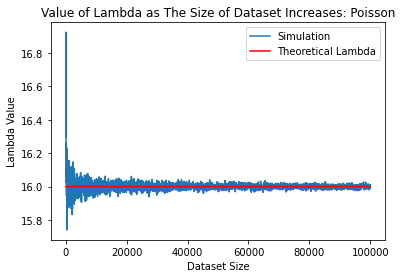

In [ ]:
plt.plot(size,max_ll_list,label="Simulation")
plt.plot(size,[16 for i in range(len(size))],color='r',label="Theoretical Lambda")
plt.title("Value of Lambda as The Size of Dataset Increases: Poisson")
plt.xlabel("Dataset Size")
plt.ylabel("Lambda Value")
plt.legend()

#Negative Binomial

In [ ]:
def max_ll_nb(r,xi):
  return (r*len(xi))/(sum(xi)+(len(xi)*r))

In [ ]:
assert max_ll_nb(1,[1]) == 0.5
assert max_ll_nb(2,[2]) == 0.5

In [ ]:
def generate_data_sets_nb(number):
  data_set = []
  for i in range(number):
    data_set.append(bin(random.randrange(1,2**32)))
  return data_set

In [ ]:
def failures_before_r_successes(r,data):
  data = data[::-1]
  data = data[:-2]
  #print(data,type(data))
  successes = 0
  trials = 0
  for i in data:
    #print(i)
    if i == "1":
      successes += 1
      if successes == r:
        break
    else:
      trials += 1
  return trials

In [ ]:
failures_before_r_successes(2,bin(100000))

6

In [ ]:
def generate_failure_data(r,num):
  data = generate_data_sets_nb(num)
  failures_data = []
  for i in data:
    failures_data.append(failures_before_r_successes(r,i))
  return max_ll_nb(r,failures_data)

In [ ]:
def data_plot_multiple_r(samp_size,r_vals):
  lambda_nb = []
  for r in r_vals:
    lambda_nb.append(generate_failure_data(r,samp_size))
  plt.scatter(r_vals,lambda_nb,label="Simulation")
  plt.hlines(0.5,1,20,colors='r',label='Theoretical Lambda')
  plt.title("Value of Lambda as the Value of r Increases: Negative Binomial")
  plt.xlabel("r Values")
  plt.ylabel("Lambda Value")
  plt.xlim(0,10)
  plt.ylim(0.2,0.8)
  plt.legend()

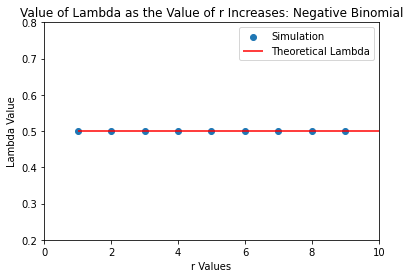

In [ ]:
data_plot_multiple_r(100000,[i for i in range(1,10)])

In [ ]:
generate_failure_data(8,10000000)

0.5001624652727822

In [ ]:
generate_failure_data(2,2)

[4, 0]

In [ ]:
generate_data_sets_nb(1)

['0b101001101001101110011000111111']

In [9]:
fib = [0,1]
a = 0
for i in range(100000):
  a = fib[len(fib)-1] + fib[len(fib)-2]
  fib.append(a)
zeros_in_fib = []
for i in fib:
  zeros_in_fib.append(count_zeros(bin(i)))


100002
4 a


Text(0, 0.5, 'Count in a Dataset Size of 1000000')

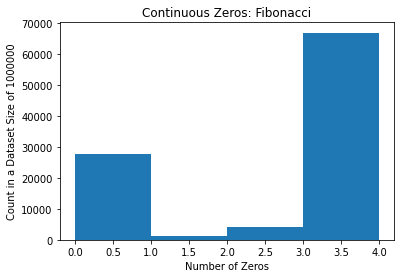

In [10]:
max_zeros = []
for i in zeros_in_fib:
  max_zeros.append(count_zeros(bin(i)))

print(len(max_zeros))
print(max(max_zeros),'a')
plt.hist(max_zeros,4)
plt.title("Continuous Zeros: Fibonacci")
plt.xlabel("Number of Zeros")
plt.ylabel("Count in a Dataset Size of 1000000")

In [11]:
def get_random_fib_dataset(size):
  dataset = []
  for i in range(size):
    dataset.append(zeros_in_fib[random.randint(1,len(zeros_in_fib)-1)])
  dataset_max = []
  for i in dataset:
    dataset_max.append(count_zeros(bin(i)))
  return dataset_max

In [12]:
def get_random_fib_pois_data(size):
  dataset = []
  for i in range(size):
    dataset.append(zeros_in_fib[random.randint(1,len(zeros_in_fib)-1)])
  dataset_max = count_ones(dataset)
  return dataset_max

In [13]:
def plot_data(max):
  x = []
  y_exponential = []
  y_poisson = []
  y_geometric = []
  for i in range(10,max,30):
    data = get_random_fib_dataset(i)
    data_2 = get_random_fib_pois_data(i)
    x.append(i)
    y_exponential.append(ll_expo(data,len(data)))
    y_poisson.append(poisson_ll(data_2))
    y_geometric.append(ll_geometric(len(data),data))
  plt.plot(x,y_exponential,label="Simulation")
  plt.title("Value of Lambda as The Size of Fib Dataset Increases: Exponential")
  plt.plot([i for i in range(100000)],[0.47515960611169294 for i in range(100000)],color='r',label="Theoretical Lambda")
  plt.xlabel("Dataset Size")
  plt.ylabel("Lambda Value")
  plt.legend()
  plt.figure()

  plt.plot(x,y_poisson,label="Simulation")
  plt.title("Value of Lambda as The Size of Fib Dataset Increases: Poisson")
  plt.plot([i for i in range(100000)],[0.4613035 for i in range(100000)],color='r',label="Theoretical Lambda")
  plt.xlabel("Dataset Size")
  plt.ylabel("Lambda Value")
  plt.legend()
  plt.figure()

  plt.plot(x,y_geometric,label="Simulation")
  plt.title("Value of Lambda as The Size of Fib Dataset Increases: Geometric")
  plt.plot([i for i in range(100000)],[0.3221072514072866 for i in range(100000)],color='r',label="Theoretical Lambda")
  plt.xlabel("Dataset Size")
  plt.ylabel("Lambda Value")
  plt.legend()
  plt.figure()

In [19]:
data = get_random_fib_dataset(10000000)

In [27]:
d = get_random_fib_pois_data(10000000)
poisson_ll(d)

0.4613035

In [19]:
ll_geometric(len(data),data)

0.3221072514072866

In [20]:
ll_expo(data,len(data))

0.47515960611169294

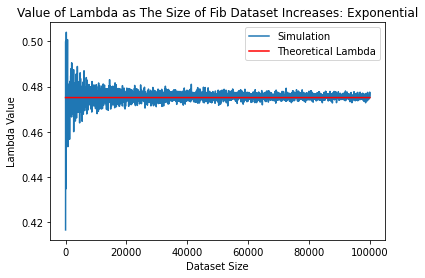

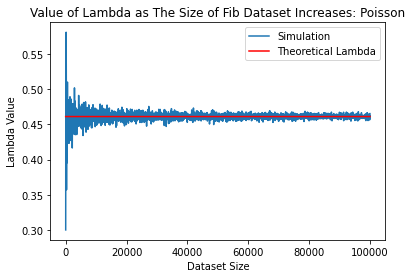

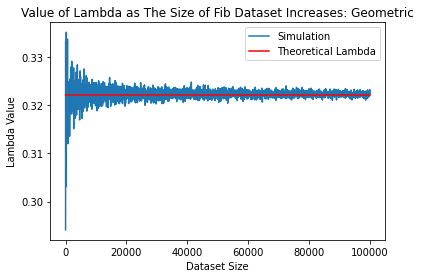

<Figure size 432x288 with 0 Axes>

In [14]:
plot_data(100000)